# Can routine lab chemistry verify a wine's cultivar? Softmax regression versus k-nearest neighbors

**Governing question.** Given the 13 chemical measurements a lab already records for a wine sample, can we reliably identify which of three grape cultivars it came from—and which of two student-built classifiers is the better basis for a verification tool?

**Intended user.** A quality-control analyst who receives a bottle with a *declared* cultivar and wants an independent check. A useful answer lets the analyst confirm most samples automatically and send only ambiguous ones for expert tasting or further testing. A wrong answer either wastes expert time (false alarm) or lets a mislabeled sample through (missed mismatch).

> **Project status.** This notebook is the first *vertical slice* of the final project. The wine data are a well-understood stand-in used to build and verify the student algorithms end to end; the same notebook structure will be re-run on the project's own dataset once that choice is approved.

**Road map.** §1 fixes the investigation contract; §2–3 audit and explore the data with specific questions; §4 sets the train/test boundary and baseline; §5 derives both models; §6 verifies the student implementations; §7 selects hyperparameters by cross-validation and evaluates once on the sealed test set; §8 dissects the failures; §9 makes a production decision.

## 1. Investigation contract

| Item | Decision |
| --- | --- |
| Observation unit | One chemically analyzed wine sample |
| Population | Wines from three cultivars grown in one Italian region (Forina et al.); results do **not** transfer to other regions or grapes without new data |
| Target | `cultivar` ∈ {0, 1, 2} |
| Information at prediction time | All 13 chemistry measurements; no label leakage because every feature is measured in the lab before any cultivar judgment |
| Kind of work | Predictive classification, not causal: chemistry *distinguishes* cultivars, it does not explain why |
| Cost of errors | A false mismatch costs analyst time; a missed mismatch lets mislabeling through. Both matter, so no class is privileged |
| Why these algorithms | Softmax regression tests whether the classes are separated by *linear* boundaries and yields calibrated-ish probabilities; k-NN makes no linearity assumption and asks whether *similar chemistry implies the same cultivar*. Their comparison tells us which geometric assumption fits the data |

**Non-goals.** Detecting fraud in other regions, predicting quality or price, or explaining the chemistry of cultivars.

The next cell loads everything through the project package: the versioned configuration, the validated data adapter, and the student algorithm registry.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.metrics import balanced_accuracy_score, confusion_matrix
from sklearn.model_selection import RepeatedStratifiedKFold, cross_val_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

from dsm_project.algorithms import (
    MajorityClassifier,
    create_student_algorithm,
    registered_student_algorithms,
)
from dsm_project.algorithms.student.logistic import cross_entropy_objective
from dsm_project.config import load_config
from dsm_project.data import load_project_dataset
from dsm_project.evaluation import bootstrap_metric_interval
from dsm_project.experiments import (
    evaluate_supervised_estimator,
    fit_supervised_candidate,
    split_supervised_task,
)

CONFIG_PATH = Path("configs/project.toml")
TASK_KEY = "classification"

config = load_config(CONFIG_PATH)
dataset = load_project_dataset(config)
task = dataset.tasks[TASK_KEY]
frame = dataset.observations

print("provenance:", dataset.provenance)
print("task:", task.name, "| target:", task.target_column, "| metric:", task.metric)
print("registered student algorithms:", registered_student_algorithms())

provenance: DatasetProvenance(name='Wine recognition', source='UCI Machine Learning Repository (Forina et al., 1991) via scikit-learn load_wine', license='CC BY 4.0 (UCI Machine Learning Repository)', observation_unit='one chemically analyzed wine sample from one of three cultivars')
task: identify cultivar from chemistry | target: cultivar | metric: balanced_accuracy
registered student algorithms: ('batch_linear_regression', 'k_nearest_neighbors', 'softmax_regression')


## 2. Data provenance and fitness for purpose

- **Source.** UCI Machine Learning Repository, *Wine* dataset (Forina et al., 1991), loaded offline through `sklearn.datasets.load_wine`. License: CC BY 4.0.
- **Sampling.** 178 wines from three cultivars of one Italian region, analyzed in one laboratory program. We do not know how bottles were selected, so we treat the sample as a convenience sample.
- **Measurements.** Alcohol (% vol), malic acid, ash, alcalinity of ash, magnesium, total phenols, flavanoids, nonflavanoid phenols, proanthocyanins, color intensity, hue, OD280/OD315 of diluted wines, and proline. Units differ by three orders of magnitude (proline is in the hundreds, hue near 1).
- **Validation boundary.** `ExampleWineAdapter` adds a unique `observation_id` and `ProjectDataset.validate()` checks identifiers and declared columns before any model sees the data.

The compact audit below checks types, missing values, and cardinality rather than printing raw rows.

In [2]:
audit = pd.DataFrame(
    {
        "dtype": frame.dtypes.astype(str),
        "missing": frame.isna().sum(),
        "unique": frame.nunique(dropna=False),
    }
)
print(f"rows={len(frame):,}, columns={frame.shape[1]}")
display(audit)

rows=178, columns=15


,dtype,missing,unique
observation_id,int64,0,178
alcohol,float64,0,126
malic_acid,float64,0,133
ash,float64,0,79
alcalinity_of_ash,float64,0,63
magnesium,float64,0,53
total_phenols,float64,0,97
flavanoids,float64,0,132
nonflavanoid_phenols,float64,0,39
proanthocyanins,float64,0,101


There are no missing values and the identifier is unique, so no imputation step is needed. Every feature is continuous.

## 3. Purposeful exploration

We explore to answer three questions that change the modeling plan:

1. **Are the classes balanced?** If not, plain accuracy would reward predicting the majority class.
2. **Are feature scales comparable?** k-NN distances and a single gradient-descent step size are both sensitive to units.
3. **Are the classes plausibly separable?** If two or three features already separate them, linear boundaries may be enough.

{0: 59, 1: 71, 2: 48} | largest/smallest std ratio: 2530


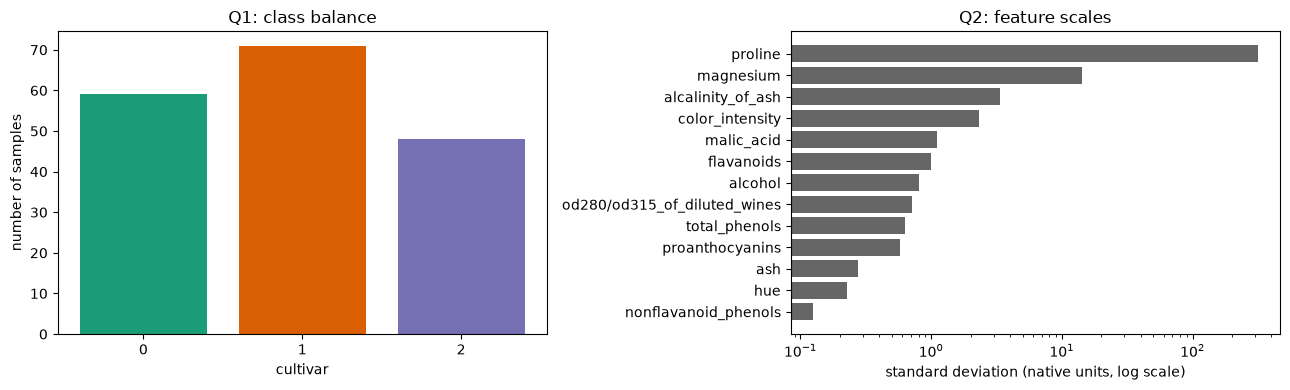

In [3]:
features = frame.loc[:, task.feature_columns]
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

counts = frame[task.target_column].value_counts().sort_index()
axes[0].bar(counts.index.astype(str), counts.values, color=["#1b9e77", "#d95f02", "#7570b3"])
axes[0].set(xlabel="cultivar", ylabel="number of samples", title="Q1: class balance")

spread = features.std().sort_values()
axes[1].barh(spread.index, spread.values, color="#666666")
axes[1].set_xscale("log")
axes[1].set(xlabel="standard deviation (native units, log scale)", title="Q2: feature scales")
plt.tight_layout()
print(counts.to_dict(), "| largest/smallest std ratio:", round(spread.iloc[-1] / spread.iloc[0]))

**Q1.** The classes are moderately imbalanced (48 to 71 samples). We therefore use **balanced accuracy**, which averages the recall of each class, so a classifier that ignores cultivar 2 cannot score well.

**Q2.** Feature standard deviations span more than three orders of magnitude; proline alone would dominate any Euclidean distance. Both models will be fitted inside a pipeline with `StandardScaler`, fitted on training folds only. (§8 measures what happens if we skip this.)

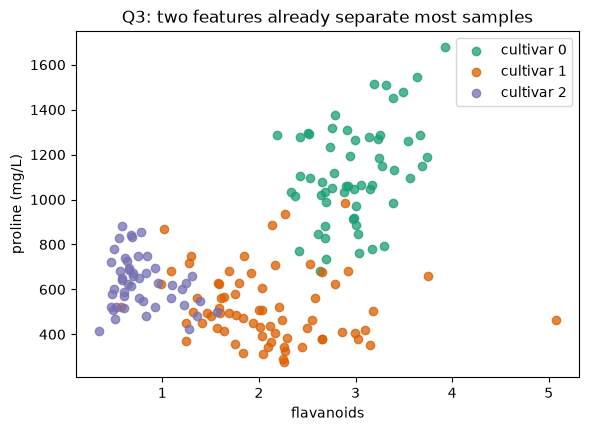

In [4]:
fig, ax = plt.subplots(figsize=(6.5, 4.5))
for label, color in zip(range(3), ["#1b9e77", "#d95f02", "#7570b3"], strict=True):
    rows = frame[task.target_column] == label
    ax.scatter(frame.loc[rows, "flavanoids"], frame.loc[rows, "proline"],
               label=f"cultivar {label}", alpha=0.75, color=color)
ax.set(xlabel="flavanoids", ylabel="proline (mg/L)", title="Q3: two features already separate most samples")
ax.legend();

**Q3.** Just two features place most samples in distinct regions, with overlap mainly between cultivars 1 and 2 at low proline. That suggests (a) near-linear separability in 13 dimensions, so softmax regression is a reasonable hypothesis, and (b) local neighborhoods are mostly pure, so k-NN should also work. The overlap region is where we expect errors. This plot does **not** prove separability in held-out data; only the evaluation below can.

## 4. Experimental boundaries and baseline

- **Split.** `split_supervised_task` draws one stratified 75/25 split (seed 438 from the config): **133 development rows** and **45 sealed test rows**. The test rows are used exactly once, in §7, after all choices are frozen.
- **Model selection.** Hyperparameters are chosen by 5-fold stratified cross-validation repeated 5 times (25 fits per candidate) *inside the development rows only*. The scaler is part of each pipeline, so it is re-fitted on every training fold—no leakage of test-fold statistics.
- **Baseline.** `MajorityClassifier` always predicts the most frequent training class. Any useful model must beat it by a wide margin.
- **Metric.** For $K$ classes with recall $r_k = \frac{\text{correct predictions in class } k}{\text{samples in class } k}$,

$$
\text{balanced accuracy} = \frac{1}{K}\sum_{k=1}^{K} r_k \in [0, 1],
$$

which equals $1/K = 0.33$ for the majority baseline regardless of imbalance.

In [5]:
split = split_supervised_task(dataset, config, task_name=TASK_KEY)
dev_x, dev_y = split.train_features, split.train_targets
print("development rows:", len(dev_x), "| sealed test rows:", len(split.test_features))
print("test class counts:", split.test_targets.value_counts().sort_index().to_dict())

development rows: 133 | sealed test rows: 45
test class counts: {0: 15, 1: 18, 2: 12}


## 5. Mathematical model

**Notation.** Sample $i$ has standardized features $x_i \in \mathbb{R}^{d}$ ($d = 13$) and label $y_i \in \{0, 1, 2\}$ ($K = 3$); $Y$ is the $n \times K$ one-hot label matrix.

### 5.1 Softmax (multinomial logistic) regression

Each class $k$ gets a linear score $z_{ik} = x_i^\top w_k + b_k$. Scores become probabilities through the softmax

$$
P(y_i = k \mid x_i) = p_{ik} = \frac{e^{z_{ik}}}{\sum_{j=1}^{K} e^{z_{ij}}}.
$$

We fit $W \in \mathbb{R}^{d\times K}$ and $b \in \mathbb{R}^{K}$ by minimizing the mean cross-entropy with an L2 (ridge) penalty on $W$:

$$
J(W, b) = -\frac{1}{n}\sum_{i=1}^{n}\sum_{k=1}^{K} Y_{ik}\log p_{ik} + \frac{\lambda}{2}\lVert W\rVert_F^2 .
$$

Differentiating (the softmax and log cancel neatly) gives

$$
\nabla_W J = \frac{1}{n}X^\top(P - Y) + \lambda W, \qquad \nabla_b J = \frac{1}{n}\mathbf{1}^\top(P - Y),
$$

and batch gradient descent repeats $W \leftarrow W - \eta\nabla_W J$, $b \leftarrow b - \eta\nabla_b J$. $J$ is convex, so a small enough step $\eta$ reaches the global minimum. **Why the penalty matters here:** if the classes are perfectly separable and $\lambda = 0$, scaling $W$ up always lowers $J$, so no finite minimizer exists and gradient descent never converges. Any $\lambda > 0$ makes the minimizer finite and unique. Cost: $O(ndK)$ per iteration; prediction needs only $W$ and $b$.

### 5.2 k-nearest neighbors

k-NN stores the training set. For a query $x$, let $N_k(x)$ be the $k$ training indices with the smallest Euclidean distance $\lVert x - x_j\rVert_2$. The prediction is the majority label among them:

$$
\hat{y}(x) = \arg\max_{c}\sum_{j\in N_k(x)} \mathbb{1}[y_j = c].
$$

There is no objective to optimize; $k$ controls the bias–variance trade-off ($k = 1$ memorizes noise; large $k$ blurs class boundaries). Prediction costs $O(nd)$ per query and requires keeping all training data. The method assumes that **distance in standardized chemistry space reflects cultivar similarity**.

*Reference:* Hastie, Tibshirani & Friedman, *The Elements of Statistical Learning*, 2nd ed., §4.4 (logistic regression) and §13.3 (nearest neighbors).

## 6. Student implementation and verification

Both estimators are student-authored and registered in `dsm_project.algorithms.registry`:

| Registry name | Class | Source | Tests |
| --- | --- | --- | --- |
| `softmax_regression` | `SoftmaxRegression` | `src/dsm_project/algorithms/student/logistic.py` | `tests/test_student_algorithms.py` |
| `k_nearest_neighbors` | `KNearestNeighborsClassifier` | `src/dsm_project/algorithms/student/neighbors.py` | `tests/test_student_algorithms.py` |

Both follow the scikit-learn estimator interface (`fit`, `predict`, `predict_proba`), so they compose with `StandardScaler` in a pipeline. Both validate shapes and finiteness, reject use before fitting, and are deterministic. `SoftmaxRegression` computes the softmax with the max-subtraction trick and the loss with log-sum-exp, records `loss_history_`, `n_iter_`, and `converged_`, and raises `FloatingPointError` instead of silently returning NaNs if a too-large step size makes it diverge. `KNearestNeighborsClassifier` breaks distance ties by training order and vote ties by the smallest label.

**Evidence in the test suite:**

- *Analytic cases:* softmax of equal scores is uniform; the loss at $W = 0$ equals $\log K$; with an uninformative feature the fitted probabilities equal the class frequencies; a hand-computed 3-NN vote on a number line.
- *Gradient check:* the analytic gradient matches central finite differences to $10^{-7}$ (repeated live below).
- *Differential tests against trusted scikit-learn:* `SoftmaxRegression(l2_penalty=λ)` matches `LogisticRegression(C = 1/(nλ))` probabilities to $10^{-5}$ on the full wine data, since both minimize the same objective up to a constant factor; `KNearestNeighborsClassifier` matches `KNeighborsClassifier(algorithm="brute")` probabilities exactly for several $k$, metrics, and weightings.
- *Failure modes:* invalid hyperparameters, misaligned targets, non-finite inputs, too few classes, too large $k$, wrong feature count at prediction.

In [6]:
# Live gradient check: compare the analytic gradient with central differences.
rng = np.random.default_rng(0)
x_small = rng.normal(size=(12, 4))
y_small = np.eye(3)[rng.integers(0, 3, size=12)]
w0, b0, lam, h = rng.normal(size=(4, 3)), rng.normal(size=3), 0.1, 1e-6

_, grad_w, _ = cross_entropy_objective(w0, b0, x_small, y_small, lam)
numeric = np.zeros_like(w0)
for idx in np.ndindex(w0.shape):
    step = np.zeros_like(w0)
    step[idx] = h
    up, _, _ = cross_entropy_objective(w0 + step, b0, x_small, y_small, lam)
    down, _, _ = cross_entropy_objective(w0 - step, b0, x_small, y_small, lam)
    numeric[idx] = (up - down) / (2 * h)
print(f"max |analytic - numeric| = {np.abs(grad_w - numeric).max():.2e}")

max |analytic - numeric| = 3.14e-10


The analytic and numerical gradients agree to roughly $10^{-10}$, far below what could change an optimization step, so the derivation in §5.1 is implemented correctly.

Next we check the claim from §5.1 that the ridge penalty is what makes the fit converge on these (nearly separable) data. We fit on the development rows with several values of $\lambda$ and record the objective trace and final weight norm.

,lambda,converged,iterations,‖W‖_F,final objective
0,0.00,False,20000,11.2626,0.0003
1,0.01,True,2974,3.1179,0.0905
2,0.10,True,426,1.5945,0.2827


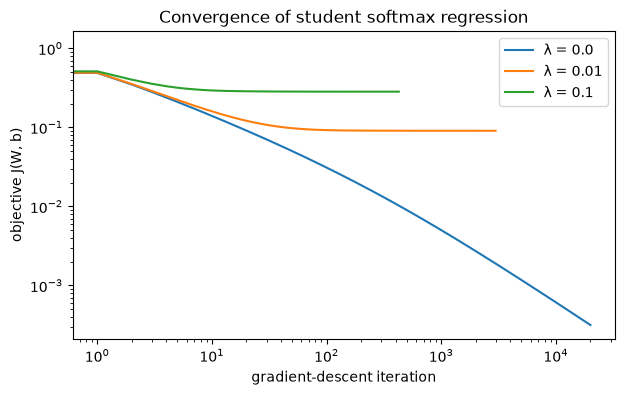

In [7]:
scaled_dev = StandardScaler().fit_transform(dev_x)
fig, ax = plt.subplots(figsize=(7, 4))
rows = []
for lam in [0.0, 0.01, 0.1]:
    model = create_student_algorithm(
        "softmax_regression", l2_penalty=lam, learning_rate=0.5, max_iterations=20_000
    ).fit(scaled_dev, dev_y)
    ax.plot(model.loss_history_, label=f"λ = {lam}")
    rows.append({"lambda": lam, "converged": model.converged_, "iterations": model.n_iter_,
                 "‖W‖_F": np.linalg.norm(model.coef_), "final objective": model.loss_history_[-1]})
ax.set(xscale="log", yscale="log", xlabel="gradient-descent iteration",
       ylabel="objective J(W, b)", title="Convergence of student softmax regression")
ax.legend()
display(pd.DataFrame(rows).round(4))

With $\lambda = 0$ the objective keeps falling toward zero, the weight norm keeps growing, and the run hits the iteration cap without converging—exactly the separable-data behavior predicted in §5.1. With $\lambda > 0$ the objective flattens at a positive value and the gradient-norm tolerance is reached. A model with unbounded weights also produces over-confident probabilities, which would be harmful for a tool whose purpose is to flag *uncertain* samples.

## 7. Results, uncertainty, and practical meaning

### 7.1 Model selection on development data only

We cross-validate the baseline, softmax regression over $\lambda \in \{0.001, 0.01, 0.1, 1\}$, and k-NN over $k \in \{1, 3, 5, 7, 9, 11, 15, 21\}$. **Selection rule (fixed before looking):** highest mean CV balanced accuracy within each family; ties go to the more regularized model (larger $\lambda$ or larger $k$).

In [8]:
cv = RepeatedStratifiedKFold(n_splits=5, n_repeats=5, random_state=438)


def cv_scores(estimator):
    return cross_val_score(estimator, dev_x, dev_y, cv=cv, scoring="balanced_accuracy")


candidates = {"baseline: majority": MajorityClassifier()}
for lam in [0.001, 0.01, 0.1, 1.0]:
    candidates[f"student softmax λ={lam}"] = make_pipeline(
        StandardScaler(),
        create_student_algorithm("softmax_regression", l2_penalty=lam, learning_rate=0.5),
    )
for k in [1, 3, 5, 7, 9, 11, 15, 21]:
    candidates[f"student k-NN k={k}"] = make_pipeline(
        StandardScaler(), create_student_algorithm("k_nearest_neighbors", n_neighbors=k)
    )

cv_table = pd.DataFrame(
    [{"candidate": name, "mean": s.mean(), "std": s.std()}
     for name, s in ((name, cv_scores(est)) for name, est in candidates.items())]
).set_index("candidate")
display(cv_table.round(3))

,mean,std
candidate,,
baseline: majority,0.333,0.000
student softmax λ=0.001,0.983,0.023
student softmax λ=0.01,0.985,0.024
student softmax λ=0.1,0.988,0.022
student softmax λ=1.0,0.981,0.025
student k-NN k=1,0.944,0.027
student k-NN k=3,0.951,0.033
student k-NN k=5,0.969,0.033
student k-NN k=7,0.969,0.026


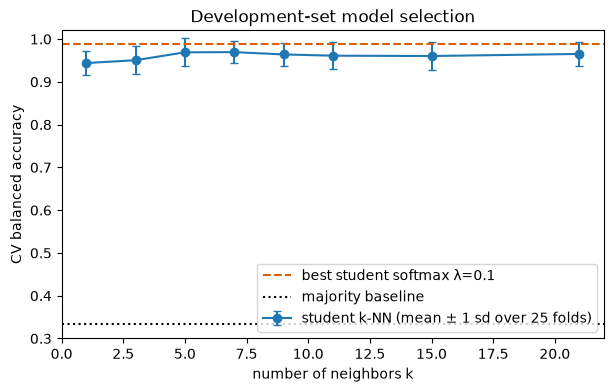

In [9]:
knn_rows = cv_table.filter(like="k-NN", axis=0)
ks = [int(name.split("k=")[1]) for name in knn_rows.index]
best_softmax = cv_table.filter(like="softmax", axis=0)["mean"].idxmax()

fig, ax = plt.subplots(figsize=(7, 4))
ax.errorbar(ks, knn_rows["mean"], yerr=knn_rows["std"], marker="o", capsize=3,
            label="student k-NN (mean ± 1 sd over 25 folds)")
ax.axhline(cv_table.loc[best_softmax, "mean"], color="#d95f02", linestyle="--",
           label=f"best {best_softmax}")
ax.axhline(cv_table.loc["baseline: majority", "mean"], color="black", linestyle=":",
           label="majority baseline")
ax.set(xlabel="number of neighbors k", ylabel="CV balanced accuracy",
       title="Development-set model selection", ylim=(0.3, 1.02))
ax.legend(loc="lower right");

**Reading the evidence.** Both families are far above the 0.33 baseline. Softmax regression is insensitive to $\lambda$ across two orders of magnitude (≈0.98–0.99), with $\lambda = 0.1$ best. k-NN improves from $k = 1$ (≈0.94, noisy memorization) to a plateau around $k = 5$–$7$ (≈0.97). The fold-to-fold standard deviation (≈0.02–0.03) is about as large as the gap between the families, so the CV evidence *slightly* favors softmax regression but does not establish a decisive difference.

**Frozen choices:** `softmax_regression(l2_penalty=0.1)` and `k_nearest_neighbors(n_neighbors=7)`.

### 7.2 One evaluation on the sealed test set

Now, and only now, both selected student models, the baseline, and the matching trusted scikit-learn references are evaluated once on the 45 test rows through the same `evaluate_supervised_estimator` boundary. Bootstrap intervals (2,000 resamples of the test rows) show how much a 45-row estimate can move.

In [10]:
final_candidates = {
    "baseline: majority": MajorityClassifier(),
    "student: softmax λ=0.1": make_pipeline(
        StandardScaler(),
        create_student_algorithm("softmax_regression", l2_penalty=0.1, learning_rate=0.5,
                                 max_iterations=20_000),
    ),
    "student: k-NN k=7": make_pipeline(
        StandardScaler(), create_student_algorithm("k_nearest_neighbors", n_neighbors=7)
    ),
}
results = {
    name: evaluate_supervised_estimator(dataset, config, task_name=TASK_KEY,
                                        estimator_name=name, estimator=estimator)
    for name, estimator in final_candidates.items()
}
for reference in ("logistic_regression", "neighbors"):
    result = fit_supervised_candidate(dataset, config, task_name=TASK_KEY, model_name=reference)
    results[result.model_name] = result

rows = []
for name, result in results.items():
    interval = bootstrap_metric_interval(result.observed, result.predictions,
                                         balanced_accuracy_score)
    rows.append({"model": name, "balanced accuracy": result.metric_value,
                 "95% CI low": interval.lower, "95% CI high": interval.upper,
                 "errors": int((result.observed != result.predictions).sum()),
                 "test rows": result.test_rows})
final_table = pd.DataFrame(rows).set_index("model")
display(final_table.round(3))

,balanced accuracy,95% CI low,95% CI high,errors,test rows
model,,,,,
baseline: majority,0.333,0.333,0.333,27,45
student: softmax λ=0.1,0.981,0.941,1.000,1,45
student: k-NN k=7,0.981,0.941,1.000,1,45
reference:logistic_regression,0.981,0.941,1.000,1,45
reference:neighbors,0.981,0.941,1.000,1,45


**Result.** Both student models classify 44 of 45 held-out wines correctly (balanced accuracy 0.98), matching their trusted scikit-learn counterparts exactly and beating the baseline by 0.65. The bootstrap interval runs from about 0.94 to 1.00: with only 45 test rows a single extra error moves the score by about two points, so this test set **cannot** rank the two student models. Practically, either model would automatically confirm the large majority of samples; the remaining question is which one gives the analyst the better signal about *which* samples to double-check.

## 8. Failure analysis

First, where do the errors fall?

both student models miss the same test rows: True


,flavanoids,proline,color_intensity,true,predicted,p0,p1,p2
83,1.59,515.0,4.8,1,2,0.039,0.372,0.589


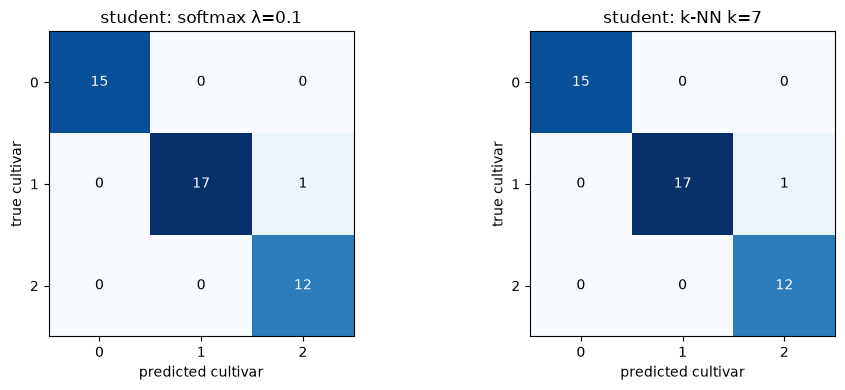

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, name in zip(axes, ["student: softmax λ=0.1", "student: k-NN k=7"], strict=True):
    result = results[name]
    matrix = confusion_matrix(result.observed, result.predictions, labels=[0, 1, 2])
    ax.imshow(matrix, cmap="Blues")
    for (i, j), value in np.ndenumerate(matrix):
        ax.text(j, i, value, ha="center", va="center",
                color="white" if value > matrix.max() / 2 else "black")
    ax.set(xticks=range(3), yticks=range(3), xlabel="predicted cultivar",
           ylabel="true cultivar", title=name)
plt.tight_layout()

softmax_result = results["student: softmax λ=0.1"]
knn_result = results["student: k-NN k=7"]
wrong = softmax_result.observed != softmax_result.predictions
same_rows = np.array_equal(wrong, knn_result.observed != knn_result.predictions)
probabilities = softmax_result.estimator.predict_proba(softmax_result.holdout_features)
misclassified = softmax_result.holdout_features.loc[wrong].assign(
    true=softmax_result.observed[wrong], predicted=softmax_result.predictions[wrong],
    p0=probabilities[wrong, 0], p1=probabilities[wrong, 1], p2=probabilities[wrong, 2],
)
print("both student models miss the same test rows:", same_rows)
display(misclassified[["flavanoids", "proline", "color_intensity", "true", "predicted",
                       "p0", "p1", "p2"]].round(3))

Both models make the **same single mistake**: a cultivar-1 sample predicted as cultivar 2. That is the overlap region already visible in §3 (low proline, low flavanoids), so the error reflects genuine chemical overlap between those two cultivars rather than an implementation defect—two models with very different assumptions, and both scikit-learn references, agree on it.

Crucially, softmax regression was **not confident** about this sample: it assigned only ≈0.59 to the wrong class. That suggests a practical safeguard: flag any sample whose top probability falls below a review threshold. The next cell shows the trade-off between how many samples an analyst must review and how many errors slip through.

,samples flagged for review,errors caught,errors passed automatically
review threshold,,,
0.5,0,0,1
0.6,2,1,0
0.7,3,1,0
0.8,9,1,0
0.9,16,1,0


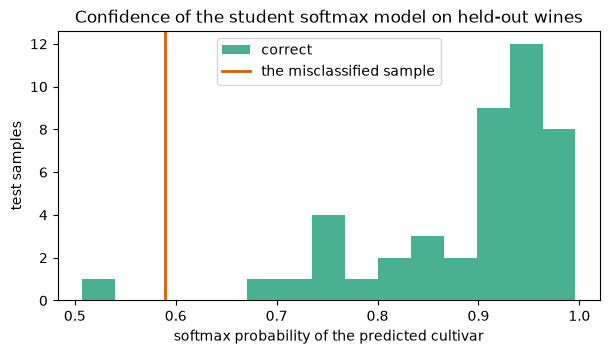

In [12]:
top_probability = probabilities.max(axis=1)
thresholds = [0.5, 0.6, 0.7, 0.8, 0.9]
trade_off = pd.DataFrame(
    [{"review threshold": t,
      "samples flagged for review": int((top_probability < t).sum()),
      "errors caught": int((wrong & (top_probability < t)).sum()),
      "errors passed automatically": int((wrong & (top_probability >= t)).sum())}
     for t in thresholds]
).set_index("review threshold")
display(trade_off)

fig, ax = plt.subplots(figsize=(7, 3.5))
ax.hist(top_probability[~wrong], bins=15, color="#1b9e77", alpha=0.8, label="correct")
ax.axvline(top_probability[wrong][0], color="#d95f02", linewidth=2, label="the misclassified sample")
ax.set(xlabel="softmax probability of the predicted cultivar",
       ylabel="test samples", title="Confidence of the student softmax model on held-out wines")
ax.legend();

A threshold of 0.7 would send a handful of the 45 samples to an expert and catch the only error. This is a tentative operating point: it was read off the test set, so it must be re-chosen on development data (or a calibration split) before deployment.

Second, how fragile is the pipeline to the preprocessing decision from §3? We re-run the k-NN cross-validation **without** standardization.

In [13]:
unscaled = cv_scores(create_student_algorithm("k_nearest_neighbors", n_neighbors=7))
scaled = cv_scores(make_pipeline(StandardScaler(),
                                 create_student_algorithm("k_nearest_neighbors", n_neighbors=7)))
print(f"k-NN k=7 CV balanced accuracy  scaled: {scaled.mean():.3f} ± {scaled.std():.3f}"
      f"   unscaled: {unscaled.mean():.3f} ± {unscaled.std():.3f}")

k-NN k=7 CV balanced accuracy  scaled: 0.969 ± 0.026   unscaled: 0.703 ± 0.077


Without scaling, k-NN falls from ≈0.97 to ≈0.70 because proline (std ≈ 315) dominates every distance. This is the most dangerous *operational* failure mode for a distance-based model: if a future data feed changes a unit (e.g., proline in g/L instead of mg/L) and the fitted scaler is not applied consistently, accuracy collapses silently. Monitoring should therefore check incoming feature ranges against the training distribution.

**Failure sources, classified.**

- *Data coverage:* one region, three cultivars, 178 samples from c. 1991—any other region or vintage is out of scope until new data are evaluated.
- *Task formulation:* genuine chemical overlap between cultivars 1 and 2 caps achievable accuracy; more features (not more model complexity) would be needed.
- *Implementation:* no defects found—student and trusted implementations agree on every test prediction.
- *Distribution shift:* unit or instrument changes are detectable by input monitoring; a change in which cultivars are submitted needs delayed labels to detect.

## 9. Conclusion and production decision

**Answer to the governing question.** Yes—within this population, 13 routine chemistry measurements identify the cultivar of about 98% of held-out samples (95% bootstrap interval ≈ 0.94–1.00), compared with 33% for a majority-class baseline. The only observed failure lies in a known chemical overlap between cultivars 1 and 2.

**Which model?** On accuracy alone the two student models are indistinguishable on the test set; cross-validation slightly favors softmax regression. We **promote `SoftmaxRegression(l2_penalty=0.1)` as the candidate for the product**, retaining k-NN as a comparison model, because it (1) gives probabilities that flagged the one error as uncertain, enabling a "confirm or send to review" workflow, (2) needs only 13 × 3 weights plus 3 intercepts at prediction time instead of the whole training set, and (3) is less exposed to feature-scale errors.

**Most important limitation.** All evidence comes from 178 wines of one region; the stand-in dataset says nothing about the final project domain.

**Next steps.**

1. Replace the stand-in with the project's own dataset (adapter, dataset card, CI fixture) and re-run this notebook unchanged in structure.
2. Choose the review threshold on development data with a calibration check, not on the test set.
3. Add the remaining applicable course algorithms (e.g., a decision tree and k-means/PCA for the unsupervised task) to the student package with the same verification standard.
4. Promote the selected student model through the artifact and API path, with input-range monitoring for the scaling failure identified in §8.